# Compressed Image Classification
In this notebook, a Image Classification model is implemented, analyzing its performance over a dataset of compressed images. The aim of the experiment is to try to make a prediction model able to classify images, starting from their compressed representation.

The idea is to use the ResNet50 model (the same used as baseline on raw images dataset), modifying it according to the new input size.
In this case, the input size consists of a single channel as input.

**Review changes:** search for `REVIEW` in this notebook. Corrections cover
configuration (`None`, v3 folder, version validation), NPZ validation,
normalization cache identity, checkpoint compatibility and optional LR changes.
The dataset formulas were corrected too. Edited code-cell outputs were cleared.
Start a new kernel and run from the top after changing VERSION or SCALE.


Safety: start each S with a fresh kernel and CHECKPOINT_NAME=None. Configuration is checked before training and saving; verified checkpoints include data_context. Failed writes retain a .partial file. Existing checkpoints are never overwritten.


In [1]:
import matplotlib.pyplot as plt
import torch

# setup the device
device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cuda'

# 1. The dataset

CIFAR-10 has 50,000 training images and 10,000 test images in 10 classes.
The GD-derived input is one uint16 cumulative-rank map of shape [224, 224].

For ordered base rank r:

$$a_r=\frac{\log_2(1+\Delta_r)}{\log_2(1+\Delta_{max})}, \qquad z_r=r+\sum_{j=1}^{r}q_j.$$

- **V2:** fixed integer S; $q_r=\lfloor S a_r\rfloor$.
- **V3:** $q_r=\lfloor S_i a_r\rfloor$; choose the largest nonnegative integer
  $S_i^*$ s.t. $K_i-1+\sum_{r=1}^{K_i-1}q_r\le65535$ for each $i^{th}$ image.
- A single-base image has an all-zero map (v3 uses $S_i=0$).

Both versions use global mean/std computed only on their own training set,
and apply the same statistics to test. No per-image rescaling is added.


### 1.1 Dataset Download
The notebook can be run locally or on Google Colab, so the dataset can be retrieved from Google Drive or kept in the project's local directory

In [2]:
from pathlib import Path
from zipfile import ZipFile
import json
import shutil
import sys

# All experiment choices are kept here.
CONFIG = {
    "version": "v3",
    "scale": None,  # Use None for v3.
    "local": True,
    "use_subsample": False,
    "checkpoint_name": None,
    "batch_size": 32,
    "learning_rate": 0.1,
    "model_seed": 42,
    "loader_seed": 2,
    "num_classes": 10,
    "colab_root": Path("/content/drive/MyDrive/Colab Notebooks/AARHUS INTERNSHIP"),
}
VERSION, SCALE = CONFIG["version"], CONFIG["scale"]
if VERSION not in ("v2", "v3"):
    raise ValueError("Select v2 or v3")
if VERSION == "v2" and (type(SCALE) is not int or not 0 <= SCALE <= 65535):
    raise ValueError("V2 requires an integer scale in 0..65535")
if VERSION == "v3" and SCALE is not None:
    raise ValueError("Set scale=None for v3")
LOCAL = CONFIG["local"]
USE_SUBSAMPLE = CONFIG["use_subsample"]
CHECKPOINT_NAME = CONFIG["checkpoint_name"]
COLAB_PROJECT_ROOT = CONFIG["colab_root"]
if not LOCAL:
    from google.colab import drive
    drive.mount("/content/drive")

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
# In Colab copy src/ml_setup to Drive, or point SOURCE_ROOT to a clone's src.
SOURCE_ROOT = PROJECT_ROOT / "src" if LOCAL else COLAB_PROJECT_ROOT / "src"
if str(SOURCE_ROOT) not in sys.path:
    sys.path.insert(0, str(SOURCE_ROOT))

REPRESENTATION = {"v2": "cumulative-rank-u16-v2", "v3": "cumulative-rank-u16-v3"}[VERSION]
EXPERIMENT = {"version": VERSION, "representation": REPRESENTATION, "scale": SCALE}
dataset_name = f"v2_cumulative_rank-s{SCALE}" if VERSION == "v2" else "v3_cumulative_rank_adaptive"
storage_base = PROJECT_ROOT / "output" if LOCAL else COLAB_PROJECT_ROOT
STORAGE_ROOT = storage_base / dataset_name
MODELS_DIR = storage_base / "models"
DATA_ROOT = STORAGE_ROOT if LOCAL else Path(
    f"/content/cifar10_v2_s{SCALE}" if VERSION == "v2" else "/content/cifar10_v3")
stats_name = "normalization_z_u16.json" if LOCAL else "normalization_full_train_z_u16.json"
if USE_SUBSAMPLE:
    DATA_ROOT = STORAGE_ROOT / "subsample"
    stats_name = "normalization_subsample_z_u16.json"
STATS_PATH = STORAGE_ROOT / stats_name
CHECKPOINT_TO_LOAD = MODELS_DIR / CHECKPOINT_NAME if CHECKPOINT_NAME is not None else None

# Only full-dataset Colab runs need to extract archives to temporary storage.
if not LOCAL and not USE_SUBSAMPLE:
    DATA_ROOT.mkdir(parents=True, exist_ok=True)
    for split in ("train", "test"):
        folder = DATA_ROOT / split
        folder.mkdir(exist_ok=True)

        source_manifest = STORAGE_ROOT / f"manifest_{split}.json"
        manifest = json.loads(source_manifest.read_text(encoding="utf-8"))
        expected = {sample["file"] for sample in manifest["samples"]}

        if any("/" in name or "\\" in name for name in expected):
            raise ValueError("Manifest filenames must not contain subdirectories.")

        missing = [
            name for name in expected
            if not (folder / name).is_file()
        ]

        if missing:
            local_zip = DATA_ROOT / f"{split}.zip"
            shutil.copy2(STORAGE_ROOT / f"{split}.zip", local_zip)

            with ZipFile(local_zip) as archive:
                members = {}

                for member in archive.infolist():
                    if member.is_dir() or not member.filename.endswith(".npz"):
                        continue

                    name = member.filename.replace("\\", "/").rsplit("/", 1)[-1]

                    if name in members:
                        raise ValueError(f"Duplicate filename in ZIP: {name}")

                    members[name] = member

                absent = expected - members.keys()
                if absent:
                    raise ValueError(
                        f"{split}: {len(absent)} manifest files missing from ZIP."
                    )

                for index, name in enumerate(missing, 1):
                    destination = folder / name
                    temporary = destination.with_suffix(".npz.part")

                    with archive.open(members[name]) as source:
                        with temporary.open("wb") as target:
                            shutil.copyfileobj(source, target)

                    temporary.replace(destination)

                    if index % 5000 == 0 or index == len(missing):
                        print(f"{split}: extracted {index}/{len(missing)} file")

            # Remove only the temporary local archive; keep the original on Drive.
            local_zip.unlink()

        shutil.copy2(source_manifest, folder / f"manifest_{split}.json")
        print(f"{split}: {len(expected)} samples")

In [3]:
# Paths are configured in the environment cell above.
print(f"Version: {VERSION}")
print("Environment:", "local" if LOCAL else "Colab")
print("Dataset Path:", DATA_ROOT)
print("Statistics Path:", STATS_PATH)
print("Models Path:", MODELS_DIR)
print("Checkpoint Path:", CHECKPOINT_TO_LOAD)


Version: v3
Environment: local
Dataset Path: C:\Users\Edward\Desktop\AARHUS\output\v3_cumulative_rank_adaptive
Statistics Path: C:\Users\Edward\Desktop\AARHUS\output\v3_cumulative_rank_adaptive\normalization_z_u16.json
Models Path: C:\Users\Edward\Desktop\AARHUS\output\models
Checkpoint Path: None


### 1.2 Upload all the dataset into variables
The class `CumulativeDataset()` allows to obtain the pairs (image,label) merging the information from the compressed images and the manifest (json file) containing the label details.
From the repository root, the existing label builder can generate them from the trusted local CIFAR archive:

```powershell
python src/build_label_manifests.py --npz-root output/DATA_ROOT
```

This command validates both splits before writing and requires the original
CIFAR archive and resized images at its configured paths. For full Colab runs,
copy the generated manifests to the Drive dataset root as `manifest_train.json`
and `manifest_test.json`, alongside `train.zip` and `test.zip`.


In [74]:
import json
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader

def load_z_map(path, experiment=None):
    experiment = EXPERIMENT if experiment is None else experiment
    version = experiment["version"]
    with ZipFile(path) as archive:
        metadata = json.loads(archive.read("metadata.json"))

    representation = metadata.get("representation", {})
    allowed = {"v2": {"cumulative-rank-u16-v1","cumulative-rank-u16-v2"}, "v3": {"cumulative-rank-u16-v3"}}
    if representation.get("name") not in allowed[version]:
        raise ValueError(f"Wrong representation for {VERSION}: {path}")

    with np.load(path, allow_pickle=False) as archive:
        z = archive["z_u16"]
    return z


class CumulativeDataset(Dataset):
    def __init__(self, manifest_path, transform=None):
        self.manifest_path = Path(manifest_path)
        self.folder = self.manifest_path.parent
        self.transform = transform
        self.experiment = EXPERIMENT.copy()
        self.manifest_sha256 = __import__("hashlib").sha256(self.manifest_path.read_bytes()).hexdigest()

        with self.manifest_path.open(encoding="utf-8") as f:
            manifest = json.load(f)

        self.samples = manifest["samples"]
        self.idx_to_class = {
            index: name
            for name, index in manifest["class_to_idx"].items()
        }

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):
        sample = self.samples[index]
        array = load_z_map(self.folder / sample["file"], self.experiment).astype(np.float32)
        image = torch.from_numpy(array).unsqueeze(0) # shape: [1, 224, 224]
        if self.transform is not None:
            image = self.transform(image)

        label = torch.tensor(sample["label"], dtype=torch.long)
        return image, label

In [ ]:
# Statistics use ONLY the training manifest, before random augmentation.
# CumulativeDataset already returns float32 tensors [1, 224, 224] in raw z units.
import json
import numpy as np
import torchvision.transforms as transforms

def find_manifest(folder, split):
    candidates = [folder / f"manifest_{split}.json", 
                  folder / "manifest.json",
                  folder / f"subsample_manifest_{split}.json"]
    found = [path for path in candidates if path.exists()]
    if len(found) != 1:
        raise ValueError(f"Expected only one manifest in {folder}, found {found}")
    return found[0]
TRAIN_MANIFEST = find_manifest(DATA_ROOT / "train", "train")
TEST_MANIFEST = find_manifest(DATA_ROOT / "test", "test")

FORCE_RECOMPUTE_STATS = False  # Set True if data change within the same configuration, or if the cache is missing or corrupted.

def training_stats(manifest_path, cache_path, force=False):
    """Compute mean and variance on the training set, unless cached statistics already exist."""

    manifest = json.loads(
        manifest_path.read_text(encoding="utf-8")
    )

    if manifest.get("split") != "train":
        raise ValueError("Normalization statistics must come from the training split.")

    samples = manifest["samples"]
    filenames = [sample["file"] for sample in samples]

    # bind cached statistics to configuration, manifest and file inventory.
    paths = [manifest_path.parent / filename for filename in filenames]
    if cache_path.exists() and not force:
        cached = json.loads(
            cache_path.read_text(encoding="utf-8")
        )

        print(f"Loaded training statistics from {cache_path}")
        return cached
  
    paths = [
        manifest_path.parent / filename
        for filename in filenames
    ]

    # Merge per-image moments in float64: global population std.
    count, mean, m2 = 0, 0.0, 0.0

    for index, path in enumerate(paths, 1):
        values = load_z_map(path).astype(np.float64)

        n = values.size
        image_mean = float(values.mean())
        image_m2 = float(np.square(values - image_mean).sum())

        new_count = count + n
        delta = image_mean - mean

        m2 += (
            image_m2
            + delta * delta * count * n / new_count
        )

        mean += delta * n / new_count
        count = new_count

        if index % 5000 == 0 or index == len(paths):
            print(
                f"Training statistics: "
                f"{index}/{len(paths)} images"
            )

    std = float(np.sqrt(m2 / count))

    if not np.isfinite(std) or std <= 0:
        raise ValueError(
            "Training standard deviation is zero or non-finite."
        )

    stats = dict(
        schema=f"z_u16-normalization-{VERSION}",
        experiment=EXPERIMENT.copy(),
        #dataset_fingerprint=dataset_fingerprint,
        training_manifest=manifest_path.name,
        num_images=len(paths),
        num_pixels=count,
        mean=float(mean),
        std=std,
        units="raw z_u16 values; no division by 65535",
        ddof=0,
    )

    temporary = cache_path.with_suffix(".json.tmp")

    temporary.write_text(
        json.dumps(stats, indent=2) + "\n",
        encoding="utf-8"
    )

    temporary.replace(cache_path)

    print(f"Saved training statistics to {cache_path}")

    return stats


normalization_stats = training_stats(
    TRAIN_MANIFEST, STATS_PATH, force=FORCE_RECOMPUTE_STATS
)
CHANNEL_MEAN = normalization_stats["mean"]
CHANNEL_STD = normalization_stats["std"]
print(f"Training mean={CHANNEL_MEAN:.6f}, std={CHANNEL_STD:.6f} (raw z units)")

# Inputs are already tensors and 224x224; Resize is normally a no-op.
# Do not add ToTensor() or divide by 65535: the statistics are in raw z units.
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.Normalize(mean=[CHANNEL_MEAN], std=[CHANNEL_STD]),
])
test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.Normalize(mean=[CHANNEL_MEAN], std=[CHANNEL_STD]),
])


Loaded training statistics from C:\Users\Edward\Desktop\AARHUS\output\v2_cumulative_rank-s2\normalization_z_u16.json
Training mean=1524.683301, std=2870.027249 (raw z units)


In [81]:
train_data = CumulativeDataset(TRAIN_MANIFEST, transform=train_transform) 
test_data = CumulativeDataset(TEST_MANIFEST, transform=test_transform)
assert train_data.idx_to_class == test_data.idx_to_class
print(f"Training samples: {len(train_data)}; test samples: {len(test_data)}")

Training samples: 50000; test samples: 10000


# 2. Batches generation and check their validity

In [ ]:
BATCH_SIZE = CONFIG["batch_size"]
train_generator = torch.Generator().manual_seed(CONFIG["loader_seed"])
train_loader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True,
                          generator=train_generator, num_workers=0)
test_loader = DataLoader(test_data, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
print(f"Train: {len(train_loader)} batches; test: {len(test_loader)} batches")


Plot some of the "images":

Images: torch.Size([32, 1, 224, 224]); labels: torch.Size([32])


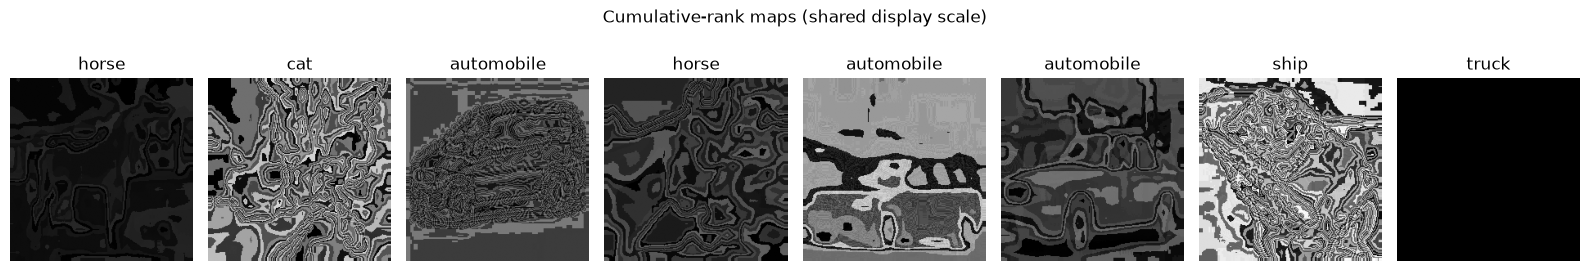

In [83]:

x, y = next(iter(train_loader))
print(f"Images: {x.shape}; labels: {y.shape}")
# These are feature maps, not reconstructed RGB images.
raw_maps = x * CHANNEL_STD + CHANNEL_MEAN
count = min(8, len(raw_maps))
fig, axes = plt.subplots(1, count, figsize=(2 * count, 3), squeeze=False)
vmax = max(float(raw_maps[:count].max()), 1.0)
for i, axis in enumerate(axes[0]):
    axis.imshow(raw_maps[i, 0].numpy(), cmap="gray", vmin=0, vmax=vmax)
    axis.set_title(train_data.idx_to_class[y[i].item()])
    axis.axis("off")
fig.suptitle("Cumulative-rank maps (shared display scale)")
plt.tight_layout()
plt.show()


As it can be seen, some of the objects are still recognizable in the image, meaning that (in some samples) the compression kept the spatial information of the shapes.

Check batch validity:

In [84]:
images, labels = next(iter(train_loader))

print(images.shape)  # torch.Size([32, 1, 224, 224])
print(images.dtype)  # torch.float32

print(labels.shape) # torch.Size([32])
print(labels.dtype) # torch.int64
print(labels[:5])

print([
    train_data.idx_to_class[label.item()]
    for label in labels[:5]
])

torch.Size([32, 1, 224, 224])
torch.float32
torch.Size([32])
torch.int64
tensor([5, 3, 6, 7, 0])
['dog', 'cat', 'frog', 'horse', 'airplane']


# 3. The Model: Pre-Trained ResNet50
In a first try, the ResNet50 model is used. At first, only a fine tuning of the first and the last layers, for make the size compatible, is made

### Custom ResNet50 for single-channel input + additional features

We need to define a custom ResNet50 class that extends `torchvision.models.ResNet` to:

1.  **Modify the first convolutional layer (`conv1`)**: Change its `in_channels` from 3 (for RGB) to 1 (for `rank_cumulative_delta` channel). When loading pre-trained weights, we'll exclude the original `conv1` weights and initialize the new `conv1` layer.
2.  **Modify the final fully connected layer (`fc`)**: Edited to provide classification over the 10 classes.

In [ ]:
# Run once for a new experiment OR to restore a checkpoint.
# Do not rerun this cell when merely adding epochs in the current session.
import math
import torch.nn as nn
from ml_setup.models import CustomResNet50

INITIAL_LR = CONFIG["learning_rate"]
torch.manual_seed(CONFIG["model_seed"])

checkpoint = None 
if CHECKPOINT_TO_LOAD is not None:
    checkpoint = torch.load(CHECKPOINT_TO_LOAD, map_location="cpu", weights_only=True)
    if checkpoint.get("version") != VERSION or checkpoint.get("representation") != REPRESENTATION:
        raise ValueError("Checkpoint version/representation differs (legacy checkpoints need explicit migration).")
    if checkpoint.get("scale") != SCALE:
        raise ValueError("Checkpoint scale differs from the selected experiment.")
    for key, current in (("mean", CHANNEL_MEAN), ("std", CHANNEL_STD)):
        if not math.isclose(checkpoint["normalization"][key], current, rel_tol=1e-9):
            raise ValueError("Normalization differs: select the same dataset/statistics before resuming.")

resnet_single_channel = CustomResNet50(num_classes=CONFIG["num_classes"], pretrained=checkpoint is None,
                                      in_channels=1).to(device)
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(
    (p for p in resnet_single_channel.parameters() if p.requires_grad), lr=INITIAL_LR
)
history = []
test_metrics = None
if checkpoint is not None:
    resnet_single_channel.load_state_dict(checkpoint["model_state_dict"], strict=True)
    optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
    history = checkpoint["history"]
    if checkpoint["completed_epochs"] != len(history):
        raise ValueError("Checkpoint epoch count and history disagree.")
    test_metrics = checkpoint.get("test_metrics")

print("Completed epochs:", len(history))
print("Total parameters:", sum(p.numel() for p in resnet_single_channel.parameters()))
print("Trainable parameters:", sum(p.numel() for p in resnet_single_channel.parameters() if p.requires_grad))
resnet_single_channel.eval()
with torch.inference_mode():
    check_logits = resnet_single_channel(images[:2].to(device))
assert check_logits.shape == (min(2, len(images)), CONFIG["num_classes"])
assert torch.isfinite(check_logits).all()
if checkpoint is not None:
    torch.set_rng_state(checkpoint["torch_rng_state"])
    train_generator.set_state(checkpoint["loader_rng_state"])
    if torch.cuda.is_available() and checkpoint.get("cuda_rng_states"):
        if len(checkpoint["cuda_rng_states"]) == torch.cuda.device_count():
            torch.cuda.set_rng_state_all(checkpoint["cuda_rng_states"])
print("Model ready. Run the single training cell to add epochs.")


# 4. Functions
Some functions helpful for repeated workflows

### 4.1 Training, testing and timing

Shared helpers return metrics; train_step also returns training_seconds.
The epoch loop and confusion-matrix plot remain below in the notebook.

In [ ]:
from ml_setup.helper_functions import train_step, test_step, summarize_training_time


# 5. Training and Test loops


In [96]:
# REVIEW: optional LR change; preserve the restored optimizer and its state.
NEW_LR = 0.001  # Set a positive value (e.g. 0.01) to change LR explicitly.
if NEW_LR is not None:
    for group in optimizer.param_groups:
        group["lr"] = NEW_LR
print("Current learning rates:", [group["lr"] for group in optimizer.param_groups])


Current learning rates: [0.001]


In [ ]:
# SINGLE TRAINING LOOP: every execution adds ADDITIONAL_EPOCHS.
# Keep the existing model, optimizer and history; no reset here.
from tqdm.auto import tqdm
from timeit import default_timer as timer



ADDITIONAL_EPOCHS = 5
if not isinstance(ADDITIONAL_EPOCHS, int) or ADDITIONAL_EPOCHS < 1:
    raise ValueError("ADDITIONAL_EPOCHS must be a positive integer")
start_epoch = len(history)
end_epoch = start_epoch + ADDITIONAL_EPOCHS
start_time = timer()
test_metrics = None  # Any previous test result refers to older weights.
for epoch in tqdm(range(start_epoch + 1, end_epoch + 1)):
    print(f"\nEpoch {epoch}/{end_epoch}")
    metrics = train_step(resnet_single_channel, train_loader, loss_fn, optimizer, device)
    history.append({"epoch": epoch, "loss": float(metrics["loss"]),
                    "accuracy": float(metrics["accuracy"]),
                    "lr": float(optimizer.param_groups[0]["lr"]),
                    "training_seconds": metrics["training_seconds"],
                    "training_device": str(device)})
print(f"Completed epochs: {len(history)}; elapsed: {timer() - start_time:.1f}s")
# Fixed learning rate: the held-out test does not guide training.


Plot the behavior of the training loss function and the training accuracy

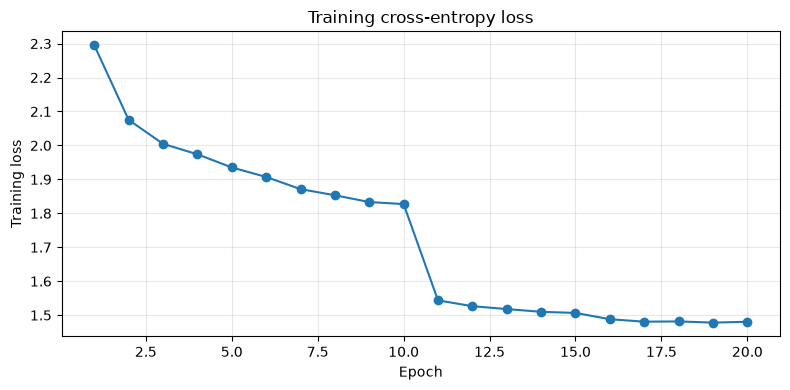

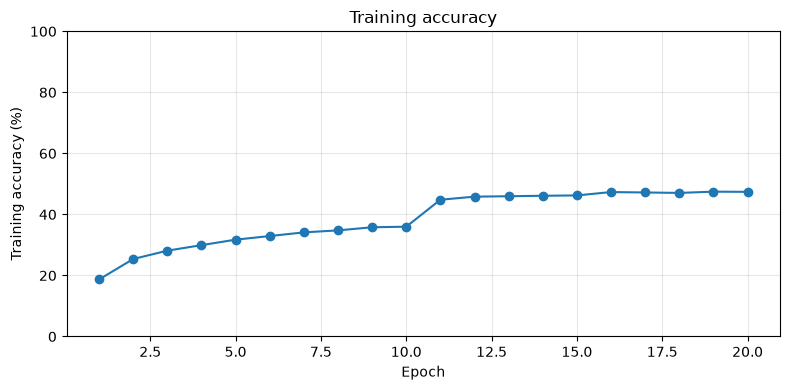

In [98]:
# Learning curves over ALL completed epochs, including restored history.
if not history:
    raise ValueError("Train or load a checkpoint with history first.")
epoch_numbers = [entry["epoch"] for entry in history]
fig_loss, ax_loss = plt.subplots(figsize=(8, 4))
ax_loss.plot(epoch_numbers, [entry["loss"] for entry in history], marker="o")
ax_loss.set(xlabel="Epoch", ylabel="Training loss", title="Training cross-entropy loss")
ax_loss.grid(alpha=0.3)
fig_loss.tight_layout()
plt.show()

fig_accuracy, ax_accuracy = plt.subplots(figsize=(8, 4))
ax_accuracy.plot(epoch_numbers, [entry["accuracy"] for entry in history], marker="o")
ax_accuracy.set(xlabel="Epoch", ylabel="Training accuracy (%)",
                title="Training accuracy", ylim=(0, 100))
ax_accuracy.grid(alpha=0.3)
fig_accuracy.tight_layout()
plt.show()


Compute prediction over the test set and plot a confusion matrix

In [ ]:
# Evaluate the current weights on test; do not use this to tune hyperparameters.
# Rows = true classes, columns = predicted classes. Each supported row sums to 1.
import numpy as np

num_classes = CONFIG["num_classes"]
class_names = [test_data.idx_to_class[i] for i in range(num_classes)]

evaluation = test_step(resnet_single_channel, test_loader, loss_fn, device,
                       num_classes=num_classes)

confusion_counts = np.asarray(evaluation["confusion_counts"], dtype=np.int64)
support = confusion_counts.sum(axis=1, keepdims=True)
confusion_proportions = np.divide(confusion_counts, support,
    out=np.zeros_like(confusion_counts, dtype=np.float64), where=support != 0)
test_metrics = {"epoch": len(history), "loss": evaluation["loss"],
    "accuracy": evaluation["accuracy"],
    "confusion_counts": confusion_counts.tolist(),
    "confusion_proportions": confusion_proportions.tolist()}
fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(confusion_proportions, cmap="Blues", vmin=0, vmax=1)
fig.colorbar(im, ax=ax, label="Proportion within true class")
ax.set(xticks=range(num_classes), yticks=range(num_classes),
       xticklabels=class_names, yticklabels=class_names,
       xlabel="Predicted class", ylabel="True class",
       title=f"Test confusion matrix - epoch {len(history)}")
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
for i in range(num_classes):
    for j in range(num_classes):
        value = confusion_proportions[i, j]
        label = f"{value:.1%}" if support[i, 0] else "N/A"
        ax.text(j, i, label, ha="center", va="center",
                color="white" if value > 0.5 else "black", fontsize=8)
fig.tight_layout()
plt.show()
# Diagonal = recall per class. N/A means that class is absent from this split.


# 6. Save and load the model
What we save of a model are its weights. So, when we load it back, we should create an instance of the model and set its weights with what we saved

In [ ]:
# Save to the configured persistent model directory after any additional training.
from datetime import datetime
from zoneinfo import ZoneInfo

MODELS_DIR.mkdir(parents=True, exist_ok=True)
date = datetime.now(ZoneInfo("Europe/Rome")).strftime("%Y-%m-%d")
if VERSION == "v2":
    MODEL_SAVE_PATH = MODELS_DIR / f"v2_S{SCALE}_{len(history)}epochs_{date}.pth"
elif VERSION == "v3":
    MODEL_SAVE_PATH = MODELS_DIR / f"v3_{len(history)}epochs_{date}.pth"

training_time = summarize_training_time(history)

checkpoint_to_save = {
    "schema": f"resnet-single-channel-checkpoint-{VERSION}",
    "version": VERSION,
    "representation": REPRESENTATION, 
    "scale": SCALE,  
    "model_state_dict": resnet_single_channel.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(), "num_classes": CONFIG["num_classes"],
    "completed_epochs": len(history), "history": history,
    "training_time": training_time,
    "normalization": normalization_stats,
    "idx_to_class": train_data.idx_to_class,
    "train_manifest": str(TRAIN_MANIFEST), 
    "test_manifest": str(TEST_MANIFEST),
    "test_metrics": test_metrics,
    "torch_rng_state": torch.get_rng_state(),
    "loader_rng_state": train_generator.get_state(),
    "cuda_rng_states": torch.cuda.get_rng_state_all() if torch.cuda.is_available() else [],
}

# Exclusive creation prevents accidentally replacing a previous checkpoint.
with MODEL_SAVE_PATH.open("xb") as destination:
    torch.save(checkpoint_to_save, destination)
print(f"Saved {len(history)} completed epochs to {MODEL_SAVE_PATH}")

### Load the model from Google Drive

To restore in a new session:
 1. Prepare data, normalization and the CustomResNet50 class.
 2. In the configuration cell, set CONFIG["checkpoint_name"] to the desired checkpoint filename and rerun setup.
 3. Execute that cell: it restores resnet_single_channel, optimizer and history.
 4. Execute the training cell to add epochs, or the confusion-matrix cell to evaluate.
 
Do not run a second model initialization after restoring.
